# Budget Dashboard

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
pip install sodapy

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from sodapy import Socrata
import json

In [ ]:
# Credentials removed before publishing (2026). The original cell loaded a
# Socrata API key and app token here. The revised notebook reads an optional
# token from the SOCRATA_APP_TOKEN environment variable instead.
credentials = {'app_token': None}


In [ ]:
client = Socrata("data.cityofnewyork.us", credentials['app_token'])

In [ ]:
dataset_identifier = "vn4m-mk4t"
result = client.get(dataset_identifier,
                    boro = 3,
                    limit = 100000)

The three datasets are from:

1. Register of Community Board Budget Requests https://data.cityofnewyork.us/City-Government/Register-of-Community-Board-Budget-Requests/vn4m-mk4t

2. Budget Expense https://data.cityofnewyork.us/City-Government/Expense-Budget/mwzb-yiwb

3. Discretionary Funding https://data.cityofnewyork.us/City-Government/New-York-City-Council-Discretionary-Funding/4d7f-74pe

In [ ]:
request = pd.json_normalize(result)

In [ ]:
expense = pd.read_csv('/Expense_Budget.csv')
funding = pd.read_csv('/New_York_City_Council_Discretionary_Funding.csv')

/usr/local/lib/python3.7/dist-packages/IPython/core/interactiveshell.py:2882: DtypeWarning: Columns (0,2,4,8,13) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


## 1. Register of Community Board Budget Requests

#### Function Summary

1. filter_by_CB(x,df) x: int, # of Community Board
2. filter_by_Time(x,df) x: int, Year
3. filter_by_Agency(x,df) x: str, Agency
4. keywords(df)
5. agency(df)
6. agen_keywords(df) Return a list of dictionaries with agency name and a sorted dataframe of its keywords

In [ ]:
request['publication'] = pd.to_datetime(request['publication'].astype(str))
request = request.astype({'board':'int'})

### 1.1 Filter the requests by Community Board, Publication Date, and the Agency
>Subsets can be obtained by locating a certain Community Board, Publication Date, and Agency



In [ ]:
def filter_by_CB(x,df):
    ls = []
    for i in x:
        df_sub = df[(df['board']==i)].reset_index()
        ls.append(df_sub)
    return pd.concat(ls).drop(columns=['index'])

def filter_by_Time(x,df):
    df_sub = df[pd.DatetimeIndex(df['publication']).year==x].reset_index()
    return df_sub.drop(columns=['index'])

def filter_by_Agency(x,df):
    ls = []
    for i in x:
        df_sub = df[(df['responsible_agency']==i)].reset_index()
        ls.append(df_sub)
    return pd.concat(ls).drop(columns=['index'])

In [ ]:
def agency(df):
    df = pd.DataFrame(df['responsible_agency'].value_counts())
    df.reset_index(inplace=True)
    df = df.rename(columns = {'index':'Agency','Responsible Agency':'Count'})
    return df

### 1.2 Language Analysis

This is to study the information given in columns {Request, Explanation, Response}. Keywords need to be extracted from a sentence or a short paragraph. By doing this we can get some clear and sortable information for each record of request

#### 1.2.1 NP chunking

In [ ]:
import nltk
from nltk.tree import Tree

In [ ]:
def chunking(x):
    chunkGram = """NP: {<JJ.?>*(<NN.?>|<NNS.?>)*}"""
    chunkParser = nltk.RegexpParser(chunkGram)

    tagged = nltk.pos_tag(nltk.word_tokenize(x))
    chunked = chunkParser.parse(tagged)
    ls = []
    for subtree in chunked.subtrees():
        if subtree.label() == "NP":
            unchunk = subtree.leaves()
            sentence = ""
            for token in unchunk:
                sentence += (token[0]+" ")
            ls.append(sentence.strip())
    return ls

#### 1.2.2 Find Top Keywords

In [ ]:
def keywords(d):
    breakdown = d.apply(lambda x: chunking(x['request']), axis=1)
    phrases = []
    useless = ['i.e','Reconstruct','Renovate','Provide','Repair','Assign','renovate','e.g','expand','new']
    for x in breakdown:
        for i in x:
            if i not in useless:
                phrases.append(i)
    dd = pd.Series(phrases).value_counts()
    dd = pd.DataFrame(dd)
    dd.reset_index(inplace=True)
    dd.columns = ['Keywords','Count']
    return dd

In [ ]:
def agen_keywords(d):
    agens = agency(d)['Agency']
    ls = []
    for a in agens:
        dn = filter_by_Agency([a],d)
        dic = {'Agency': a,
               'Keywords': keywords(dn)}
        ls.append(dic)
    return ls

### 1.3 Sorted List

Example:
get data from CB4, in 2021

In [ ]:
df4 = filter_by_Time(2022,request)
df4 = filter_by_CB([4,14,10,9],df4)

#### Example 1.3.1 Keywords

get the most popular keywords from the request description of CB4 in 2021

In [ ]:
  nltk.download('punkt')
  nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


True

In [ ]:
keywords(df4).head(5)

,Keywords,Count
0,Other capital budget request,93
1,park,81
2,Other expense budget request,72
3,outdoor athletic field,57
4,playground,57


#### Example 1.3.2 Agencies

get the agencies with the most requests from CB4 2021

In [ ]:
agency(df4).head(10)

,Agency,responsible_agency
0,Department of Parks and Recreation,120
1,Department of Housing Preservation & Development,81
2,Department of Education,78
3,Department of Transportation,75
4,Housing Authority,69
5,New York Public Library,51
6,Department of Sanitation,36
7,Police Department,24
8,Economic Development Corporation,24
9,Department for the Aging,24


#### Example 1.3.3 Agencies-Keywords

This is a sample chart of agency "Department of Parks and Recreation" summrized by the types of request

In [ ]:
agen = agen_keywords(df4)[0]['Agency']
agen

'Department of Education'

In [ ]:
samp = agen_keywords(df4)[0]['Keywords'].head(10)
samp

,Keywords,Count
0,elementary school,15
1,high school,15
2,DOE,12
3,interior building component,9
4,Other capital budget request,6
5,Other expense budget request,6
6,middle/intermediate school,3
7,non-teaching staff,3
8,e.g.,3
9,social,3


<function matplotlib.pyplot.show>

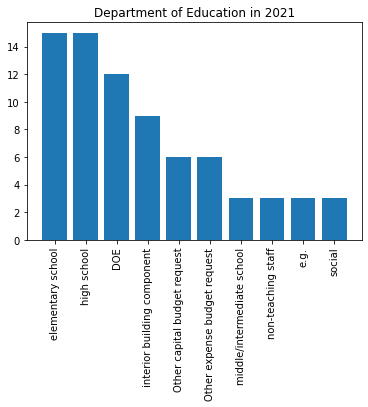

In [ ]:
k = samp['Keywords']
n = samp['Count']
p = plt.bar(k,n,align='center')
p = plt.xticks(rotation=90)
p = plt.title(agen+' in 2021')
plt.show

## 2. Budget Expense (City-wide)

This is only regarding the whole New York City because there's no information about the borough or community board

#### Function Summary
1. fil_by_Year(year,df)
2. fil_by_Agency(x,df)
3. fil_by_Type(x,df)
4. agency_e(df)
5. type_e(df)
6. agen_amount(df)

### 2.1 Filter by Fiscal Year, Type, and the Agency

In [ ]:
def fil_by_Year(year,df):
    df_sub = df[df['Fiscal Year']==year].reset_index()
    return df_sub.drop(columns=['index'])

def fil_by_Agency(x,df):
    ls = []
    for i in x:
        df_sub = df[(df['Agency Name']==i)].reset_index()
        ls.append(df_sub)
    return pd.concat(ls).drop(columns=['index'])

def fil_by_Type(x,df):
    ls = []
    for i in x:
        df_sub = df[(df['Object Class Name']==i)].reset_index()
        ls.append(df_sub)
    return pd.concat(ls).drop(columns=['index'])

### 2.2 Sorted List

In [ ]:
def agency_e(df):
    agency = df['Agency Name'].value_counts()
    dd = pd.DataFrame(agency)
    dd.reset_index(inplace=True)
    dd.columns = ['Agency','Count']
    return dd

In [ ]:
def type_e(df):
    types = df['Object Class Name'].value_counts()
    dd = pd.DataFrame(types)
    dd.reset_index(inplace=True)
    dd.columns = ['Type','Count']
    return dd

### 2.3 Summary on agency level

In [ ]:
def agen_amount(df):
    ls = []
    agen = df['Agency Name'].value_counts()
    total_cmba = df['Current Modified Budget Amount'].sum()/1000000
    for x in agen.index:
        dd = df[df['Agency Name']==x]
        cmba = dd['Current Modified Budget Amount'].sum()/1000000
        dic = {'Agency': x,
               'Adopted Budget Amount': dd['Adopted Budget Amount'].sum()/1000000,
               'Current Modified Budget Amount': cmba,
               'Financial Plan Amount': dd['Financial Plan Amount'].sum()/1000000,
               'Fraction(%)': round(100*(cmba/total_cmba),2)}
        ls.append(dic)
    dfn = pd.DataFrame(ls).sort_values(by='Current Modified Budget Amount',ascending = False)
    dfn = dfn.reset_index().drop(columns='index')
    return dfn

### Examples
get data from 2021

In [ ]:
df_exp = fil_by_Year(2021,expense)

Agencies with most records

In [ ]:
agency_e(df_exp).head(5)

,Agency,Count
0,DEPARTMENT OF HEALTH AND MENTAL HYGIENE,12387
1,DEPARTMENT OF TRANSPORTATION,7955
2,DEPARTMENT OF EDUCATION,6420
3,POLICE DEPARTMENT,6342
4,DEPARTMENT OF PARKS AND RECREATION,6278


Agencies with most budget expense (Current Modified Budget Amount as the credential)(in million$)

In [ ]:
df1 = agen_amount(df_exp).head(5)
df1

,Agency,Adopted Budget Amount,Current Modified Budget Amount,Financial Plan Amount,Fraction(%)
0,DEPARTMENT OF EDUCATION,81697.315497,84870.668263,83103.091742,28.50
1,MISCELLANEOUS,40517.232045,34630.057890,35019.838063,11.63
2,DEPARTMENT OF SOCIAL SERVICES,30770.983092,31118.804735,29263.392884,10.45
3,PENSION CONTRIBUTIONS,29889.291012,29582.484224,29798.607991,9.93
4,POLICE DEPARTMENT,16819.426092,17846.531029,16508.401214,5.99


<function matplotlib.pyplot.show>

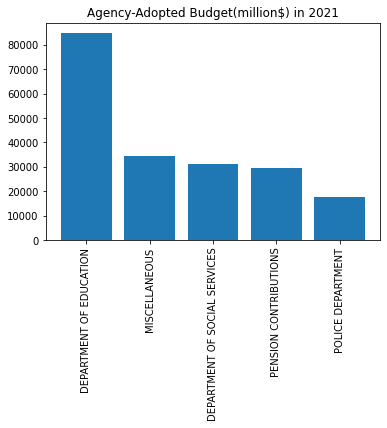

In [ ]:
plt.bar(df1['Agency'],df1['Current Modified Budget Amount'])
plt.xticks(rotation=90)
plt.title('Agency-Adopted Budget(million$) in 2021')
plt.show

([<matplotlib.patches.Wedge at 0x7f23e678c590>,
 [Text(-0.8585183207080209, 0.6877109080192637, 'DEPARTMENT OF EDUCATION'),
  Text(-0.9168385536323143, -0.6077886693361487, 'MISCELLANEOUS'),
  Text(-0.31635682521962183, -1.0535266295338537, 'DEPARTMENT OF SOCIAL SERVICES'),
  Text(0.37584978101223027, -1.0337973409295744, 'PENSION CONTRIBUTIONS'),
  Text(0.8257551067502219, -0.7267245032857568, 'POLICE DEPARTMENT'),
  Text(1.0273251944883282, -0.39319580970493456, 'DEBT SERVICE'),
  Text(0.8507705272594946, 0.6972729092303828, 'Rest')],
 [Text(-0.4682827203861931, 0.3751150407377802, '28.5%'),
  Text(-0.5000937565267168, -0.33152109236517197, '11.6%'),
  Text(-0.1725582683016119, -0.5746508888366474, '10.5%'),
  Text(0.2050089714612165, -0.5638894586888588, '9.9%'),
  Text(0.4504118764092119, -0.39639518361041276, '6.0%'),
  Text(0.5603591969936335, -0.214470441657237, '5.3%'),
  Text(0.46405665123245154, 0.3803306777620269, '28.1%')])

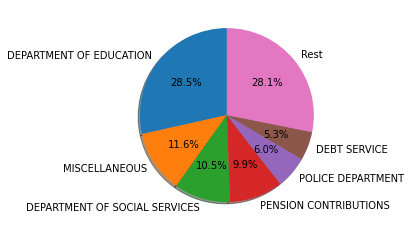

In [ ]:
da = agen_amount(df_exp)
rest = sum(da.iloc[6:,:]['Current Modified Budget Amount'])
df2 = da.head(6)
sizes = list(df2['Current Modified Budget Amount'])
sizes.append(rest)
labels = list(df2['Agency'])
labels.append('Rest')
plt.pie(sizes,labels=labels,autopct='%1.1f%%',shadow=True, startangle=90)

Types of budget requests that appear the most

In [ ]:
type_e(df_exp).head(5)

NameError: ignored

## 3. Discretionary Funding

Due to the same reason, this is only regarding the whole city

#### Function Summary
1. fil_by_Year1(year,df)
2. fil_by_Agency1(x,df)
3. fil_by_Type1(x,df)
4. agency_d(df)
5. type_d(df)
6. agen_type(x, df) Return a dictionary
7. agency_amount(df)
8. type_amount(df)

### 3.1 Filter by Agency, Fiscal Year, and Type

In [ ]:
def fil_by_Year1(year,df):
    df_sub = df[df['Fiscal Year']==year].reset_index()
    return df_sub.drop(columns=['index'])

def fil_by_Agency1(x,df):
    ls = []
    for i in x:
        df_sub = df[(df['Legal Name of Organization']==i)].reset_index()
        ls.append(df_sub)
    return pd.concat(ls).drop(columns=['index'])

def fil_by_Type1(x,df):
    ls = []
    for i in x:
        df_sub = df[(df['Source']==i)].reset_index()
        ls.append(df_sub)
    return pd.concat(ls).drop(columns=['index'])

### 3.2 Sorted List

In [ ]:
def agency_d(df):
    agency = df['Legal Name of Organization'].value_counts()
    dd = pd.DataFrame(agency)
    dd.reset_index(inplace=True)
    dd.columns = ['Agency','Count']
    return dd

def type_d(df):
    types = df['Source'].value_counts()
    dd = pd.DataFrame(types)
    dd.reset_index(inplace=True)
    dd.columns = ['Type','Count']
    return dd

def agen_type(x, df):
    dn = fil_by_Agency1([x],df)
    dic = {'Agency': x,
           'Type': type_d(dn),
           'Type(by Amount)': type_amount(dn)}
    return dic

### 3.3 Sort by Amount

In [ ]:
def agency_amount(df):
    ls = []
    agen = df['Legal Name of Organization'].value_counts()
    for x in agen.index:
        dd = df[df['Legal Name of Organization']==x]
        dic = {'Agency': x,
               'Amount ($)': dd['Amount ($)'].sum()}
        ls.append(dic)
    dfn = pd.DataFrame(ls).sort_values(by='Amount ($)',ascending = False)
    dfn = dfn.reset_index().drop(columns='index')
    return dfn

def type_amount(df):
    ls = []
    types = df['Source'].value_counts()
    for x in types.index:
        dd = df[df['Source']==x]
        dic = {'Source': x,
               'Amount ($)': dd['Amount ($)'].sum()}
        ls.append(dic)
    dfn = pd.DataFrame(ls).sort_values(by='Amount ($)',ascending = False)
    dfn = dfn.reset_index().drop(columns='index')
    return dfn

### 3.4 Examples

get data from 2021

In [ ]:
dis = fil_by_Year1(2021,funding)

#### 3.4.1 Most popular types

1. in terms of number of records
2. in terms of amount($)

In [ ]:
type_d(dis).head(5)

,Type,Count
0,Local,2932
1,Youth,899
2,Cultural After-School Adventure (CASA),704
3,Aging,514
4,Food Pantries,393


In [ ]:
type_amount(dis).head(5)

,Source,Amount ($)
0,Local,36539000.0
1,New York Immigrant Family Unity Project,16600000.0
2,Peter F. Vallone Academic Scholarship,16285469.0
3,Cultural After-School Adventure (CASA),14280000.0
4,Alternatives to Incarceration (ATI's),11878800.0


#### 3.4.2 Agencies
1. in terms of number of records
2. in terms of amount

In [ ]:
agency_d(dis).head(5)

,Agency,Count
0,Food Bank For New York City,243
1,New York City Housing Authority,202
2,Department of Education,124
3,City University of New York,84
4,Metropolitan New York Coordinating Council on ...,68


In [ ]:
agency_amount(dis).head(5)

,Agency,Amount ($)
0,City University of New York,26377964.0
1,Legal Aid Society,11089927.0
2,Brooklyn Defender Services,6081499.0
3,"Bronx Defenders, The",5749999.0
4,New York Public Library,5673750.0


#### 3.4.3 Agency-Type
1. in terms of number of records
2. in terms of amount

Name of the Agency

In [ ]:
foodbank = agen_type('Food Bank For New York City',dis)
foodbank['Agency']

'Food Bank For New York City'

In [ ]:
foodbank['Type'].head(5)

,Type,Count
0,Food Pantries,233
1,Local,4
2,Food Access and Benefits,3
3,Anti-Poverty,2
4,Speaker's Initiative,1


In [ ]:
foodbank['Type(by Amount)']

,Source,Amount ($)
0,Food Pantries,3011434.0
1,Food Access and Benefits,625000.0
2,Local,24000.0
3,Speaker's Initiative,10000.0
4,Anti-Poverty,7000.0
